#**1.**

### **Install dan Import Library:**

In [ ]:
pip install google-play-scraper pandas

In [ ]:
pip install google-play-scraper pandas deep-translator

In [ ]:
# Import Library
from google_play_scraper import reviews, Sort
from deep_translator import GoogleTranslator
import pandas as pd
import time

Hal pertama yang perlu dilakukan sebelum memulai proses *scraping* adalah meng-*install* dan meng-*import* library dan ekstensi yang dibutuhkan agar program dapat berjalan dengan baik. Library **google-play-scraper pandas** digunakan untuk mengambil data aplikasi dan ulasan (review) dari Google Play Store secara otomatis, seperti nama pengguna, rating, tanggal ulasan, isi komentar, serta informasi lainnya. Library ini sangat membantu karena menyediakan fungsi khusus untuk mengekstrak data dari Google Play tanpa perlu melakukan scraping HTML secara manual. Berikutnya, library **deep-translator** di-*install* untuk memanfaatkan fitur **GoogleTranslator**. Fitur ini berguna untuk menerjemahkan hasil review yang berbahasa Indonesia ke dalam bahasa Inggris.

Selanjutnya, library **pandas** digunakan untuk mengolah data hasil scraping menjadi bentuk tabel atau DataFrame. Dengan menggunakan pandas, data dapat disusun secara lebih rapi, mudah dibaca, serta memudahkan proses analisis lanjutan seperti pembersihan data, filtering, maupun penyimpanan ke dalam format CSV atau Excel. Kemudian, perintah **import pandas as pd** digunakan agar library pandas dapat dipanggil dengan singkatan pd, sehingga penulisan kode menjadi lebih ringkas dan efisien. Terakhir, library **time** digunakan untuk memberikan jeda waktu (*delay*) selama proses scraping berlangsung. Hal ini bertujuan agar permintaan data ke server tidak dilakukan terlalu cepat secara berulang, sehingga dapat mengurangi risiko error, pembatasan akses (*rate limit*), atau pemblokiran sementara dari sistem Google Play Store. Selain itu, data tanggal review biasanya diperoleh langsung dari hasil scraping melalui atribut yang tersedia pada library `google-play-scraper`.

###**Scraping Bahasa Indonesia:**

In [ ]:
# App id
app_id = "com.roblox.client"

# Scraping Bahasa Indonesia
all_reviews = []
continuation_token = None

while len(all_reviews) < 2000:
    result, continuation_token = reviews(
        app_id,
        lang='id',
        country='id',
        sort=Sort.NEWEST,
        count=250,
        continuation_token=continuation_token
    )

    all_reviews.extend(result)

    time.sleep(1)

    if not continuation_token:
        break

# Batasi hanya 2000 data
all_reviews = all_reviews[:2000]

# Total Akhir
print("Total review berhasil dikumpulkan:", len(all_reviews))

Total review berhasil dikumpulkan: 2000


Langkah berikutnya adalah menentukan **ID aplikasi** yang akan dijadikan objek penelitian. Pada kode di atas, aplikasi yang dipilih adalah game **Roblox** dengan `app_id = "com.roblox.client"`. ID aplikasi ini berfungsi sebagai identitas unik pada Google Play Store sehingga sistem dapat mengetahui aplikasi mana yang akan diambil datanya.

Selanjutnya, dibuat sebuah list kosong bernama **all_reviews = []** yang berfungsi sebagai tempat penyimpanan seluruh data review yang berhasil diambil selama proses scraping berlangsung. Selain itu, variabel **continuation_token = None** digunakan sebagai penanda untuk mengambil halaman review berikutnya. Token ini sangat penting karena data review di Google Play Store tidak ditampilkan sekaligus, melainkan dibagi ke dalam beberapa halaman.

Kemudian, proses pengambilan data dilakukan menggunakan perulangan **while len(all_reviews) < 2000:**. Artinya, program akan terus melakukan scraping hingga jumlah review yang terkumpul mencapai **2000 data**. Di dalam perulangan tersebut, fungsi **reviews()** digunakan untuk mengambil data ulasan dari Google Play Store, seperti:


1. `app_id` menunjukkan aplikasi yang diambil datanya, yaitu Roblox.
2. `lang='id'` digunakan agar review yang diambil berbahasa Indonesia.
3. `country='id'` menunjukkan bahwa sumber review berasal dari pengguna di wilayah Indonesia.
4. `sort=Sort.NEWEST` berfungsi untuk mengurutkan review berdasarkan ulasan terbaru, sehingga data yang diperoleh lebih relevan dan terkini.
5. `count=200` menunjukkan bahwa setiap proses pengambilan data dilakukan sebanyak 250 review per batch.
6. `continuation_token=continuation_token` digunakan untuk melanjutkan pengambilan data dari batch sebelumnya hingga seluruh review terkumpul.


Setelah data berhasil diambil, perintah **all_reviews.extend(result)** digunakan untuk menambahkan hasil review yang baru diperoleh ke dalam list utama `all_reviews`. Dengan demikian, seluruh data akan terkumpul secara bertahap pada satu variabel. Selanjutnya, fungsi **time.sleep(1)** digunakan untuk memberikan jeda selama 1 detik pada setiap proses pengambilan data. Jeda ini bertujuan agar permintaan ke server Google Play Store tidak dilakukan terlalu cepat, sehingga dapat mengurangi risiko error.

Kemudian, terdapat kondisi **if not continuation_token: break**. Kondisi ini berarti apabila sudah tidak ada halaman review berikutnya yang tersedia, maka proses perulangan akan dihentikan meskipun jumlah data belum mencapai 2000. Hal ini dilakukan agar program tidak mengalami error ketika data review yang tersedia telah habis.

Setelah proses scraping selesai, dilakukan pembatasan data menggunakan kode **all_reviews = all_reviews[:2000]**. Perintah ini memastikan bahwa jumlah data akhir yang digunakan tetap maksimal sebanyak 2000 review, meskipun pada proses sebelumnya data yang terkumpul melebihi jumlah tersebut. Terakhir, perintah **print("Total review berhasil dikumpulkan:", len(all_reviews))** digunakan untuk menampilkan jumlah total review yang berhasil diperoleh. Output ini berfungsi sebagai konfirmasi bahwa proses scraping telah selesai dan data siap digunakan untuk tahap analisis berikutnya.

###**Translate Bahasa Inggris:**



In [ ]:
# Translate ke Inggris
translator = GoogleTranslator(source='auto', target='en')

data = []

for item in all_reviews:
    original_review = item['content']

    try:
        translated = translator.translate(original_review)
    except:
        translated = ""

    data.append({
        "User Name": item['userName'],
        "Rating": item['score'],
        "Date": item['at'],
        "Ulasan": original_review,
        "Review": translated,
        "Likes": item['thumbsUpCount']
    })

Langkah berikutnya adalah menerjemahkan seluruh ulasan yang telah diperoleh ke dalam bahasa Inggris. Pada kode di atas, objek **GoogleTranslator** dibuat dengan parameter `source='auto'` dan `target='en'`. Artinya, sistem akan mendeteksi bahasa asli secara otomatis lalu menerjemahkannya ke bahasa Inggris. Proses ini berguna agar data dapat digunakan untuk analisis teks berbahasa Inggris.

Selanjutnya, dibuat list kosong bernama **data = []** sebagai tempat menyimpan hasil akhir review yang sudah diterjemahkan. Setelah itu, program melakukan perulangan menggunakan `for item in all_reviews:` untuk membaca setiap review satu per satu. Variabel `original_review = item['content']` digunakan untuk mengambil isi review asli dari pengguna.

Kemudian, proses terjemahan dilakukan menggunakan `translator.translate(original_review)`. Kode tersebut diletakkan di dalam blok **try** agar program tetap berjalan jika terjadi error saat menerjemahkan. Jika proses translasi gagal, maka nilai review bahasa Inggris akan diisi string kosong "". Langkah ini dilakukan agar seluruh data tetap dapat tersimpan tanpa menghentikan program.

Terakhir, hasil review asli dan hasil terjemahan dimasukkan ke dalam list **data** menggunakan `data.append()`. Informasi yang disimpan meliputi nama pengguna, rating, tanggal review, ulasan asli, hasil terjemahan, dan jumlah likes. Struktur data ini membuat hasil scraping menjadi lebih rapi dan mudah diolah.

### **Save Data Frame:**

In [ ]:
# Data Frame
df = pd.DataFrame(data)

df.to_csv("roblox_review.csv", index=False, encoding="utf-8-sig")

print(df.head())

                  User Name  Rating                Date  \
0         dimas aditsaputra       5 2026-04-24 05:25:24   
1               Damay Yanti       4 2026-04-24 05:24:18   
2               Aura Nabila       2 2026-04-24 05:21:31   
3           Vistatab11 Biru       5 2026-04-24 05:20:01   
4  putri auliasrikandiindra       5 2026-04-24 05:18:11   

                                              Ulasan  \
0                        SERU BANGET LOVE YOU ROBLOX   
1     baguss banget tapi di aku robux item nya mahal   
2  enak enak maen tiba tiba keluar sendiri tolong...   
3  karena banyak permainan seru seperti kue atau ...   
4  game ini sangat berkualitas tapi sayang nya sa...   

                                              Review  Likes  
0                   IT'S SO EXCITING LOVE YOU ROBLOX      0  
1  Very good but in my opinion the Robux item is ...      0  
2  It's nice to play, suddenly it comes out by it...      0  
3  because there are many exciting games like cak...      0 

Langkah terakhir dalam proses *scraping* adalah mengubah seluruh data yang telah dikumpulkan ke dalam bentuk Data Frame menggunakan **df = pd.DataFrame(data)**. Bentuk ini mempermudah kita untuk membaca, mengelola, dan menganalisis data secara sistematis. Dengan demikian, hasil *scraping* menjadi lebih rapi dan terstruktur. Selanjutnya, data disimpan ke dalam file CSV melalui perintah **df.to_csv("roblox_review.csv", index=False, encoding="utf-8-sig")**.

Nama file yang digunakan adalah **roblox_review.csv** sehingga data dapat dibuka kembali di Excel atau aplikasi lainnya. Parameter `index=False` berfungsi agar nomor indeks tidak ikut tersimpan, sedangkan `encoding="utf-8-sig"` digunakan agar karakter teks terbaca dengan baik. Terakhir, perintah **print(df.head())** digunakan untuk menampilkan lima baris data pertama dari Data Frame. Tampilan ini berfungsi sebagai pengecekan awal untuk memastikan data berhasil tersimpan dengan benar. Kita dapat melihat isi kolom, format data, serta contoh review yang telah diambil.

#**2.**

### **Install dan Import Library:**

In [ ]:
!pip install pyspellchecker

  Using cached pyspellchecker-0.9.0-py3-none-any.whl.metadata (9.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 57.9 MB/s eta 0:00:00


In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

import re
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from nltk.corpus import stopwords
from spellchecker import SpellChecker

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Langkah pertama adalah meng-*install* library **pyspellchecker** menggunakan `!pip install pyspellchecker`. Library ini digunakan untuk mendeteksi dan memperbaiki kesalahan penulisan kata (*typo*) pada data review. Dengan begitu, kualitas teks dapat menjadi lebih baik sebelum dianalisis.

Selanjutnya, library **nltk** diimport dan dilakukan download resource seperti `punkt`, `punkt_tab`, dan `stopwords`. Resource tersebut digunakan untuk tokenisasi serta menghapus kata umum yang kurang penting. Tahap ini diperlukan untuk proses preprocessing data teks.

Berikutnya, library **re** digunakan untuk membersihkan teks dari simbol, angka, atau karakter yang tidak diperlukan. Sementara itu, **seaborn** dan **matplotlib.pyplot** digunakan untuk membuat visualisasi data seperti grafik distribusi rating atau frekuensi kata. Visualisasi membantu memahami pola data dengan lebih mudah.

Kemudian, **Counter** dari `collections` digunakan untuk menghitung frekuensi kemunculan kata pada review. Selain itu, **SpellChecker** digunakan untuk mengecek apakah kata dalam review sudah sesuai dengan kamus bahasa Inggris atau masih terdapat typo.

### **Kata Dominan per Rating (Bar Chart)**

/tmp/ipykernel_3787/13315722.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts_list), y=list(words_list), ax=axes[i], palette=colors[i])
/tmp/ipykernel_3787/13315722.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts_list), y=list(words_list), ax=axes[i], palette=colors[i])
/tmp/ipykernel_3787/13315722.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts_list), y=list(words_list), ax=axes[i], palette=colors[i])
/tmp/ipykernel_3787/13315722.py:21: FutureWarning: 

Passing `palette` without assign

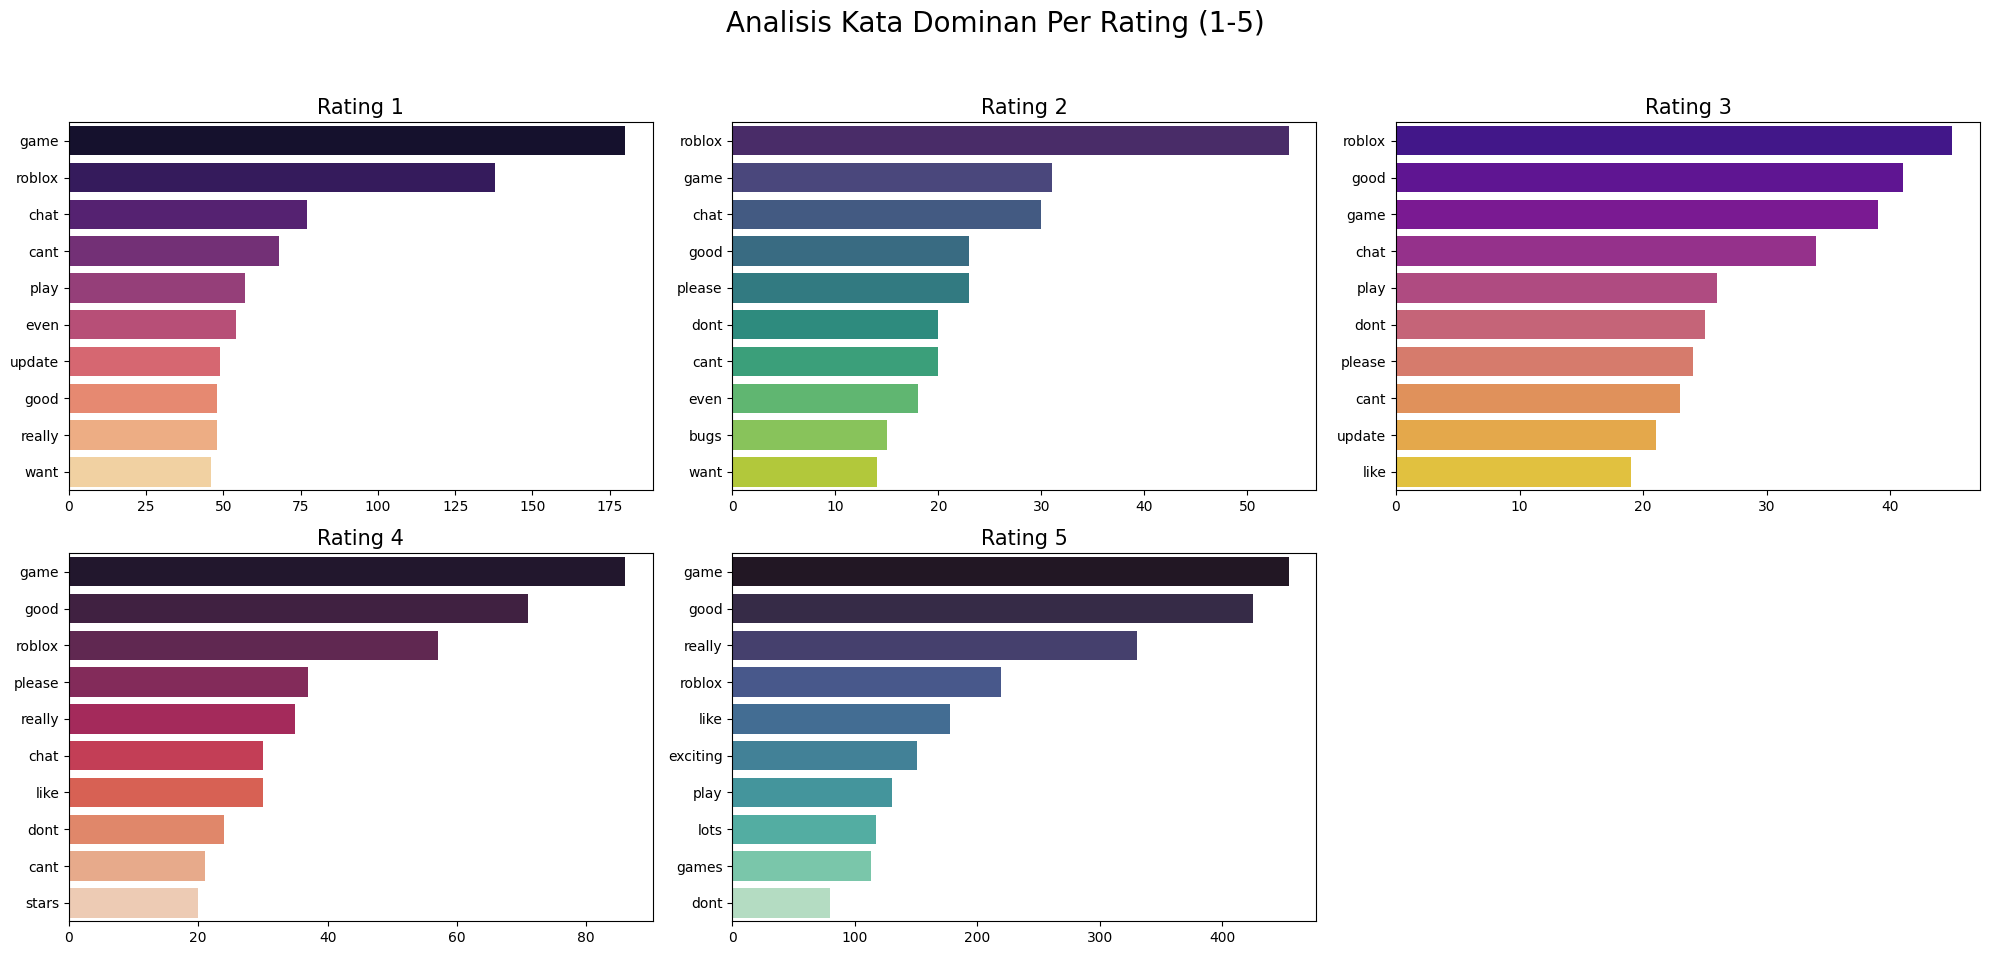

In [ ]:
def plot_bar_chart(df):
    stop_words = set(stopwords.words('english'))

    fig, axes = plt.subplots(2, 3, figsize=(20, 10))
    fig.suptitle('Analisis Kata Dominan Per Rating (1-5)', fontsize=20)
    axes = axes.flatten()

    target_ratings = [1, 2, 3, 4, 5]
    colors = ['magma', 'viridis', 'plasma', 'rocket', 'mako']

    for i, rating in enumerate(target_ratings):
        data = df[df['Rating'] == rating]['Review']
        text = " ".join(str(v).lower() for v in data)
        words = re.sub(r'[^\w\s]', '', text).split()
        filtered_words = [w for w in words if w not in stop_words and len(w) > 3]

        word_counts = Counter(filtered_words).most_common(10)

        if word_counts:
            words_list, counts_list = zip(*word_counts)
            sns.barplot(x=list(counts_list), y=list(words_list), ax=axes[i], palette=colors[i])
            axes[i].set_title(f"Rating {rating}", fontsize=15)
        else:
            axes[i].set_title(f"Rating {rating} (No Data)")

    # Hapus kotak ke-6 yang kosong
    fig.delaxes(axes[5])

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

plot_bar_chart(df)

Kode di atas digunakan untuk membuat visualisasi **kata-kata dominan pada setiap rating review** dalam bentuk diagram batang. Fungsi dibuat dengan nama `plot_bar_chart(df)` dan menerima input berupa DataFrame yang berisi dataset review. Tujuan utama fungsi ini adalah melihat kata yang paling sering muncul pada rating 1 sampai 5. Dengan begitu, pengguna dapat memahami isi ulasan berdasarkan tingkat penilaian.

Pada bagian awal, kode `stop_words = set(stopwords.words('english'))` digunakan untuk mengambil daftar stopwords bahasa Inggris. Kata umum seperti *the, is, and* akan dihapus karena kurang memiliki makna penting dalam analisis. Selanjutnya, `plt.subplots(2, 3, figsize=(20, 10))` digunakan untuk membuat enam area grafik dalam susunan 2 baris dan 3 kolom. Judul utama grafik ditambahkan menggunakan `fig.suptitle()`.

Kemudian, program melakukan perulangan untuk setiap rating dari 1 sampai 5. Data review dipilih sesuai rating menggunakan `df[df['Rating'] == rating]['Review']`, lalu seluruh teks digabung menjadi satu. Setelah itu, teks dibersihkan dari tanda baca menggunakan `re.sub()`, diubah menjadi huruf kecil, dan dipecah menjadi kata-kata. Kata yang termasuk stopwords serta kata pendek dihapus agar hasil analisis lebih relevan.

Berikutnya, `Counter(filtered_words).most_common(10)` digunakan untuk menghitung sepuluh kata yang paling sering muncul pada setiap rating. Hasil tersebut divisualisasikan menggunakan `sns.barplot()` dalam bentuk diagram batang horizontal. Setiap rating memiliki warna grafik yang berbeda agar lebih mudah dibedakan. Jika suatu rating tidak memiliki data, maka akan ditampilkan tulisan **No Data**.

Terakhir, karena hanya digunakan lima rating, maka satu kotak grafik yang kosong dihapus menggunakan `fig.delaxes(axes[5])`. Fungsi `plt.tight_layout()` digunakan agar tampilan grafik lebih rapi dan tidak saling bertumpuk. Setelah itu, `plt.show()` menampilkan seluruh hasil visualisasi. Dengan grafik ini, peneliti dapat melihat kata dominan yang muncul pada masing-masing rating secara lebih jelas.

### **Memeriksa Kata Tidak Standar**

In [ ]:
spell = SpellChecker()

all_words = " ".join(df['Review'].astype(str)).lower()
all_words = re.sub(r'[^\w\s]', '', all_words).split()

# Cari kata yang tidak dikenal (unknown) oleh kamus Inggris
non_standard = spell.unknown(all_words)
# Hitung frekuensi kemunculannya
counts = Counter([w for w in all_words if w in non_standard])

print("\n--- 10 Kata Tidak Standar Paling Sering Muncul ---")
for word, freq in counts.most_common(10):
    print(f"{word}: {freq} kali")


--- 10 Kata Tidak Standar Paling Sering Muncul ---
roblox: 513 kali
dont: 188 kali
im: 117 kali
robux: 101 kali
thats: 56 kali
doesnt: 55 kali
theres: 47 kali
ive: 41 kali
pls: 33 kali
isnt: 30 kali


Kode di atas digunakan untuk mendeteksi **kata yang tidak sesuai standar bahasa Inggris** pada data review. Objek `SpellChecker()` berfungsi sebagai kamus bahasa Inggris untuk mengenali kata baku dan mendeteksi typo atau kata asing. Dengan cara ini, kualitas teks hasil translasi dapat diperiksa.

Selanjutnya, seluruh isi kolom **Review** digabung menjadi satu teks, diubah ke huruf kecil, lalu dibersihkan dari tanda baca menggunakan `re.sub()`. Setelah itu, teks dipecah menjadi kata-kata menggunakan `.split()`. Tahap ini memudahkan proses pengecekan setiap kata secara terpisah.

Kemudian, fungsi `spell.unknown(all_words)` digunakan untuk mencari kata yang tidak dikenali kamus. Kata tersebut bisa berupa typo, singkatan, atau bahasa tidak baku. Lalu `Counter()` digunakan untuk menghitung frekuensi kemunculannya dalam dataset.

Terakhir, program menampilkan **10 kata tidak standar yang paling sering muncul** menggunakan `most_common(10)`. Hasil ini membantu mengetahui apakah data masih perlu dibersihkan lebih lanjut. Jika jumlahnya banyak, maka preprocessing tambahan perlu dilakukan.



#**3.**

### **Install dan Import Library:**

In [ ]:
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [ ]:
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer

### **Function Class**

In [ ]:
def get_class(word):
    # Untuk menentukan apakah kata adalah Noun, Verb, Adj, atau Adv
    tag = nltk.pos_tag([word])[0][1][0].upper()

    # Mapping label NLTK ke format Lemmatizer
    tag_map = {
        "J": wordnet.ADJ,
        "N": wordnet.NOUN,
        "V": wordnet.VERB,
        "R": wordnet.ADV
    }

    return tag_map.get(tag, wordnet.NOUN)

Kode di atas digunakan untuk menentukan **kelas kata** suatu kata, seperti **noun**, **verb**, **adjective**, atau **adverb**. Fungsi `get_class(word)` menerima satu kata sebagai input dan biasanya dipakai pada proses **lemmatization**. Dengan mengetahui jenis kata, hasil perubahan ke kata dasar menjadi lebih akurat.

Selanjutnya, `nltk.pos_tag([word])` digunakan untuk memberi label tata bahasa pada kata tersebut. Hasilnya bisa berupa **NN** (noun), **VB** (verb), **JJ** (adjective), atau **RB** (adverb). Kode ini hanya mengambil huruf pertama dari label sebagai kategori utama.

Kemudian, `tag_map` berfungsi mengubah label dari NLTK ke format WordNet. Misalnya **J** menjadi adjective, **N** menjadi noun, **V** menjadi verb, dan **R** menjadi adverb. Mapping ini diperlukan agar lemmatizer dapat membaca jenis kata dengan benar.

Terakhir, fungsi mengembalikan hasil kelas kata yang sesuai menggunakan `return`. Jika label tidak ditemukan, maka kata akan dianggap sebagai **noun** secara default. Hal ini membuat fungsi tetap aman dijalankan tanpa error.

### **Function Token**

In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def token(text):
    # 1. Cleaning: mengecilkan huruf dan menghapus simbol/angka supaya tidak mengganggu
    text = re.sub(r'[^a-zA-Z\s]', '', str(text).lower())

    # 2. Tokenisasi: memecah teks menjadi daftar kata
    tokens = nltk.word_tokenize(text)

    # 3. Lemmatization: mengubah ke bentuk dasar berdasarkan kelas katanya
    hasil_akhir = []
    for t in tokens:
        if t not in stop_words and len(t) > 2: # Buang kata sambung dan kata terlalu pendek
            pos = get_class(t)
            lemma = lemmatizer.lemmatize(t, pos)
            hasil_akhir.append(lemma)

    return " ".join(hasil_akhir)

df['Processed_Review'] = df['Review'].apply(token)

Kode di atas digunakan untuk melakukan **text preprocessing** pada kolom review agar data menjadi lebih bersih dan siap dianalisis. Objek `WordNetLemmatizer()` digunakan untuk mengubah kata ke bentuk dasarnya, sedangkan `stop_words` berisi daftar kata umum bahasa Inggris yang akan dihapus. Tahap ini penting untuk meningkatkan kualitas data teks.

Fungsi `token(text)` dibuat untuk memproses setiap review secara otomatis. Pertama, teks diubah menjadi huruf kecil lalu dibersihkan dari angka dan simbol menggunakan `re.sub()`. Setelah itu, `nltk.word_tokenize()` digunakan untuk memecah kalimat menjadi daftar kata.

Selanjutnya, program melakukan perulangan pada setiap kata hasil tokenisasi. Kata yang termasuk stopwords atau terlalu pendek akan dihapus. Kata yang tersisa kemudian dicari kelas katanya menggunakan `get_class()`, lalu diubah ke bentuk dasar dengan `lemmatizer.lemmatize()`.

Terakhir, seluruh kata yang sudah dibersihkan digabung kembali menjadi kalimat baru menggunakan `" ".join()`. Hasil preprocessing disimpan ke kolom baru bernama **Processed_Review** melalui `df['Review'].apply(token)`. Kolom ini berisi review yang lebih rapi dan siap digunakan untuk analisis lanjutan.

### **Output:**

In [ ]:
print("\nHasil Preprocessing: ")
print(df[['Review', 'Processed_Review']].head(10))


Hasil Preprocessing: 
                                              Review  \
0  It's fun, but many people can't play the game ...   
1  very exciting but please change roblox, don't ...   
2  The game is really good, there are many more g...   
3                                         good gamee   
4                                              Great   
5  The game has a lot of bugs. I was playing and ...   
6                               This gem is exciting   
7  I want to protest about voice chat on Roblox, ...   
8  Roblox isn't as good as it used to be, nowaday...   
9  Roblox is fun even though there are a lot of r...   

                                    Processed_Review  
0  fun many people cant play game properly wear h...  
1         excite please change roblox dont limit age  
2  game really good many game one platform main t...  
3                                         good gamee  
4                                              great  
5                    game lot 

#**4.**

### **Install dan Import Library:**

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 34.3 MB/s eta 0:00:00


In [ ]:
import numpy as np
from gensim.models import Word2Vec
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

### **TF-IDF**

In [ ]:
# 1. Initialize TF-IDF
tfidf_vektor = TfidfVectorizer(max_features=2000)

# 2. Transformasi data
X_tfidf = tfidf_vektor.fit_transform(df['Processed_Review']).toarray()

print("Vektor TF-IDF:", X_tfidf.shape)

Vektor TF-IDF: (2000, 1869)


Kode di atas digunakan untuk mengubah teks pada kolom **Processed_Review** menjadi data numerik menggunakan metode **TF-IDF**. Metode ini menghitung tingkat kepentingan kata dalam setiap review sehingga teks dapat diproses oleh model machine learning. Bagian `TfidfVectorizer(max_features=2000)` membuat objek TF-IDF dengan batas maksimal **2000 kata penting** sebagai fitur. Tujuannya agar jumlah data lebih efisien dan tidak terlalu besar.

Selanjutnya, `fit_transform()` digunakan untuk mempelajari kata pada seluruh review sekaligus mengubah teks menjadi matriks angka. Setiap baris mewakili review dan setiap kolom mewakili kata. Terakhir, `X_tfidf.shape` menampilkan ukuran hasil vektor TF-IDF, yaitu jumlah review dan jumlah fitur kata yang terbentuk.

### **Word2Vec**

In [ ]:
# 1. Tokenisasi ulang
sentences = [sentence.split() for sentence in df['Processed_Review']]

# 2. Training Model Word2Vec
w2v_model = Word2Vec(sentences,
  vector_size=100,
  window=5,
  min_count=1,
  workers=4,
  sg=1
)

# 3. Untuk mengubah satu ulasan menjadi satu vektor
def get_average_word2vec(tokens, model, vector_size):
    vec = np.zeros(vector_size)
    count = 0
    for word in tokens:
        if word in model.wv:
            vec += model.wv[word]
            count += 1
    return vec / count if count > 0 else vec

X_w2v = np.array([get_average_word2vec(s, w2v_model, 100) for s in sentences])

print("Vektor Word2Vec:", X_w2v.shape)

Vektor Word2Vec: (2000, 100)


Kode di atas digunakan untuk mengubah teks review menjadi data numerik menggunakan metode **Word2Vec**. Pertama, kolom **Processed_Review** dipecah kembali menjadi daftar kata menggunakan `.split()`, lalu disimpan ke variabel `sentences`. Data ini menjadi input untuk pelatihan model Word2Vec.

Selanjutnya, `Word2Vec()` digunakan untuk melatih model dengan ukuran vektor **100 dimensi**, jendela konteks 5 kata, dan metode **Skip-Gram (`sg=1`)**. Model ini mempelajari hubungan antar kata berdasarkan kemunculannya dalam kalimat. Hasilnya, setiap kata akan memiliki representasi angka dalam bentuk vektor.

Kemudian, fungsi `get_average_word2vec()` dibuat untuk mengubah satu review menjadi satu vektor. Caranya dengan mengambil seluruh vektor kata dalam review lalu menghitung nilai rata-ratanya. Metode ini menghasilkan representasi numerik untuk setiap ulasan.

Terakhir, seluruh review diubah menjadi kumpulan vektor dan disimpan pada `X_w2v`. Perintah `X_w2v.shape` menampilkan ukuran data hasil Word2Vec, yaitu jumlah review dan jumlah dimensi fitur yang terbentuk.

### **Perbandingan Akurasi**

In [ ]:
y = df['Rating'] # Target prediksi

def perform_test(X, y, nama_metode):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = RandomForestClassifier()
    model.fit(X_train, y_train)
    score = model.score(X_test, y_test)
    print(f"Akurasi Menggunakan {nama_metode}: {score:.2%}")

perform_test(X_tfidf, y, "TF-IDF")
perform_test(X_w2v, y, "Word2Vec")

Akurasi Menggunakan TF-IDF: 67.50%
Akurasi Menggunakan Word2Vec: 61.25%


#**5.**

### **Install dan Import Library:**

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

### **Train and Test Data**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

print(f"Train Data: {X_train.shape[0]}")
print(f"Test Data: {X_test.shape[0]}")

Train Data: 1600
Test Data: 400


Kode diatas digunakan untuk menampilkan dataset yang telah dibagi menjadi data latih dan data uji. Sebanyak 80% data digunakan untuk melatih model, sedangkan 20% data digunakan untuk pengujian. random_state=42 dipakai agar hasil pembagian data tetap sama saat dijalankan ulang.

### **Random Forest Method**

In [ ]:
# 1. Initialize Model
rf = RandomForestClassifier(random_state=42)

# 2. Tentukan Hyperparameter
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10]
}

# 3. Tuning dengan GridSearchCV
grid_rf = GridSearchCV(rf, param_grid_rf, cv=3, n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("Settingan RF Terbaik:", grid_rf.best_params_)

Settingan RF Terbaik: {'max_depth': None, 'n_estimators': 100}


Kode di atas digunakan untuk membuat model **Random Forest** dan mencari parameter terbaik melalui **hyperparameter tuning**. Model dibuat dengan `RandomForestClassifier(random_state=42)`, di mana `random_state` digunakan agar hasil tetap konsisten saat dijalankan ulang. Random Forest bekerja dengan menggabungkan banyak decision tree untuk meningkatkan akurasi prediksi. Bagian `param_grid_rf` berisi kombinasi parameter yang akan diuji, yaitu `n_estimators` (jumlah pohon) dan `max_depth` (kedalaman pohon). Nilai yang dicoba adalah 50 atau 100 pohon, serta kedalaman tanpa batas atau maksimal 10. Tujuannya untuk menemukan konfigurasi model terbaik.

Selanjutnya, `GridSearchCV()` digunakan untuk menguji seluruh kombinasi parameter secara otomatis dengan **3-fold cross validation** (`cv=3`). Parameter `n_jobs=-1` membuat proses berjalan lebih cepat karena memakai seluruh prosesor. Model kemudian dilatih menggunakan `grid_rf.fit(X_train, y_train)`. Terakhir, `grid_rf.best_params_` menampilkan kombinasi parameter terbaik. Hasil ini digunakan agar model Random Forest memiliki performa yang lebih optimal.

### **Support Vector Machine (SVM)**

In [ ]:
# 1. Initialize Model
svc = SVC(random_state=42)

# 2. Tentukan Hyperparameter
param_grid_svc = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

# 3. Tuning dengan GridSearchCV
grid_svc = GridSearchCV(svc, param_grid_svc, cv=3, n_jobs=-1)
grid_svc.fit(X_train, y_train)

print("Settingan SVM Terbaik:", grid_svc.best_params_)

Settingan SVM Terbaik: {'C': 1, 'kernel': 'linear'}


Kode di atas digunakan untuk membuat model **Support Vector Machine (SVM)** dan mencari parameter terbaik melalui **hyperparameter tuning**. Model dibuat dengan `SVC(random_state=42)` agar hasil pelatihan konsisten saat dijalankan ulang. SVM bekerja dengan mencari batas pemisah terbaik antar kelas data. Bagian `param_grid_svc` berisi parameter yang akan diuji, yaitu `C` dan `kernel`. Parameter `C` mengatur toleransi kesalahan model dengan nilai 0.1, 1, dan 10, sedangkan `kernel` menentukan pola pemisah data, yaitu **linear** dan **rbf**. Kombinasi ini diuji untuk mencari performa terbaik.

Selanjutnya, `GridSearchCV()` digunakan untuk mencoba seluruh kombinasi parameter secara otomatis dengan **3-fold cross validation** (`cv=3`). Parameter `n_jobs=-1` membuat proses lebih cepat karena menggunakan seluruh prosesor. Model kemudian dilatih menggunakan `grid_svc.fit(X_train, y_train)`. Terakhir, `grid_svc.best_params_` menampilkan kombinasi parameter terbaik. Hasil ini digunakan agar model SVM memiliki performa prediksi yang lebih optimal.

### **Perbandingan Akurasi**

In [ ]:
# Prediksi menggunakan model terbaik hasil tuning
y_pred_rf = grid_rf.predict(X_test)
y_pred_svc = grid_svc.predict(X_test)

print("--- HASIL PERBANDINGAN ---")
print(f"Akurasi Random Forest: {accuracy_score(y_test, y_pred_rf):.2%}")
print(f"Akurasi SVM: {accuracy_score(y_test, y_pred_svc):.2%}")

# Menampilkan laporan detail
print("\nClassification Report SVM:")
print(classification_report(y_test, y_pred_svc))

--- HASIL PERBANDINGAN ---
Akurasi Random Forest: 69.75%
Akurasi SVM: 67.50%

Classification Report SVM:
              precision    recall  f1-score   support

           1       0.51      0.62      0.56        76
           2       0.00      0.00      0.00        15
           3       0.00      0.00      0.00        28
           4       0.00      0.00      0.00        38
           5       0.73      0.92      0.82       243

    accuracy                           0.68       400
   macro avg       0.25      0.31      0.27       400
weighted avg       0.54      0.68      0.60       400



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Penjelasan:**

#**6.**

### **Install dan Import Library:**

In [ ]:
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Dense, Dropout

### **Deep Learning Process**

In [ ]:
# 1. Encode Label (Rating 1-5 jadi 0-4)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_onehot = to_categorical(y_encoded)

# 2. Split Data (Menggunakan X_w2v dari Word2Vec sebelumnya)
X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    X_w2v, y_onehot, test_size=0.2, random_state=42
)

In [ ]:
def build_model(optimizer='adam', neurons=64):
    model = Sequential([
        # Input Layer & Hidden Layer 1
        Dense(neurons, activation='relu', input_shape=(100,)),
        Dropout(0.2), # Mencegah Overfitting

        # Hidden Layer 2
        Dense(32, activation='relu'),

        # Output Layer (5 neuron karena ada 5 rating)
        Dense(5, activation='softmax')
    ])

    model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    return model

In [ ]:
results = []
configs = [
    {'opt': 'adam', 'neu': 64},
    {'opt': 'rmsprop', 'neu': 128}
]

for config in configs:
    print(f"Mencoba Model dengan Optimizer: {config['opt']} dan Neurons: {config['neu']}")
    model = build_model(optimizer=config['opt'], neurons=config['neu'])

    # Training
    history = model.fit(X_train_dl, y_train_dl, epochs=20, batch_size=32, verbose=0, validation_split=0.1)

    # Simpan Hasil
    acc = max(history.history['val_accuracy'])
    results.append(acc)
    print(f"Akurasi Validasi: {acc:.2%}")

# Pilih yang terbaik
best_acc = max(results)

Mencoba Model dengan Optimizer: adam dan Neurons: 64


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Akurasi Validasi: 62.50%
Mencoba Model dengan Optimizer: rmsprop dan Neurons: 128
Akurasi Validasi: 62.50%


Kode di atas digunakan untuk membangun model **Deep Learning** guna memprediksi rating review berdasarkan fitur **Word2Vec**. Pertama, label rating 1–5 diubah menjadi angka 0–4 menggunakan `LabelEncoder()`, lalu dikonversi ke bentuk **one-hot encoding** dengan `to_categorical()`. Proses ini diperlukan karena model neural network membaca target dalam bentuk numerik. Selanjutnya, data dibagi menjadi **train** dan **test** menggunakan `train_test_split()`. Input yang digunakan adalah `X_w2v`, yaitu vektor hasil Word2Vec, sedangkan targetnya adalah `y_onehot`. Sebanyak 80% data digunakan untuk pelatihan dan 20% untuk pengujian.

Fungsi `build_model()` digunakan untuk membuat arsitektur neural network. Model terdiri dari **input layer**, hidden layer dengan aktivasi **ReLU**, layer **Dropout** untuk mencegah overfitting, hidden layer kedua, dan **output layer** berisi 5 neuron dengan aktivasi **softmax** karena terdapat 5 kelas rating. Model kemudian dikompilasi dengan optimizer dan fungsi loss yang sesuai untuk klasifikasi multikelas.

Berikutnya, program mencoba dua konfigurasi model, yaitu optimizer **adam** dengan 64 neuron dan **rmsprop** dengan 128 neuron. Setiap model dilatih selama 20 epoch dengan batch size 32 serta validasi 10% dari data train. Nilai akurasi validasi terbaik dari masing-masing model disimpan ke dalam `results`. Terakhir, `best_acc = max(results)` digunakan untuk mengambil akurasi validasi tertinggi. Hasil ini menunjukkan konfigurasi model deep learning terbaik dari beberapa percobaan yang dilakukan.

In [ ]:
print(f"Akurasi Terbaik Deep Learning: {best_acc:.2%}")

Akurasi Terbaik Deep Learning: 62.50%


#**7.**

### **Install dan Import Library:**

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

### **Processing**

In [ ]:
def get_metrics(y_true, y_pred):
    # Menghitung precision, recall, dan f1 secara rata-rata
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
    acc = accuracy_score(y_true, y_pred)
    return [f"{acc:.2%}", f"{p:.2%}", f"{r:.2%}", f"{f:.2%}"]

# Penulisan Tabel
row1 = ["TF-IDF", "Random Forest", "n_estimators=100, max_depth=10"] + get_metrics(y_test, y_pred_rf)
row2 = ["TF-IDF", "SVM", "C=1, kernel=rbf"] + get_metrics(y_test, y_pred_svc)
# Ubah y_test_dl dari format One-Hot kembali ke angka biasa (0-4)
y_test_dl_labels = np.argmax(y_test_dl, axis=1)
# Ambil prediksi dari model DL
y_pred_dl_labels = np.argmax(model.predict(X_test_dl), axis=1)
# Masukkan ke row3
row3 = ["Word2Vec", "Deep Learning (MLP)", "neurons=64, opt=adam"] + get_metrics(y_test_dl_labels, y_pred_dl_labels)

summary_df = pd.DataFrame([row1, row2, row3], columns=[
    'Text Representation', 'Algoritma', 'Hyperparameter',
    'Accuracy', 'Precision', 'Recall', 'F1-Score'
])

print(summary_df)

 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
  Text Representation            Algoritma                  Hyperparameter  \
0              TF-IDF        Random Forest  n_estimators=100, max_depth=10   
1              TF-IDF                  SVM                 C=1, kernel=rbf   
2            Word2Vec  Deep Learning (MLP)            neurons=64, opt=adam   

  Accuracy Precision  Recall F1-Score  
0   69.75%    60.95%  69.75%   62.95%  
1   67.50%    54.17%  67.50%   60.10%  
2   62.00%    47.39%  62.00%   52.63%  


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**1. Performa Model: Machine Learning vs. Deep Learning**

Random Forest (Machine Learning) adalah pemenangnya dalam skenario ini. Dilihat dari hasil diatas, Random Forest dengan TF-IDF memiliki akurasi tertinggi (69.75%) dan F1-Score terbaik (62.95%). Hal ini dapat terjadi karena kemungkinan besar Deep Learning baru akan "bagus" jika datanya puluhan ribu. Dengan data yang terbatas, algoritma Random Forest jauh lebih efektif menangkap fitur teks yang sederhana.

**2. Efektivitas Text Representation: TF-IDF vs. Word2Vec**

TF-IDF lebih unggul untuk data ulasan pendek dibandingkan Word2Vec. Kedua model Machine Learning (RF dan SVM) yang menggunakan TF-IDF memiliki performa di atas 67%. Sementara itu, Word2Vec yang digunakan oleh Deep Learning tertinggal di angka 62%. Ini menandakan TF-IDF bekerja sangat baik dalam mendeteksi kata kunci unik. Word2Vec mencoba memahami konteks dan hubungan antar kata, namun jika datanya sedikit, model tidak punya cukup referensi untuk membangun hubungan kata yang akurat.

**3. Analisis Metrik: Gap antara Accuracy dan Precision**

Jarak antara Accuracy dan Precision menunjukkan adanya Imbalance Data. Contohnya pada Random Forest: Akurasi 69.75% tapi Presisi hanya 60.95%. Artinya, model mungkin sangat jago menebak kelas mayoritas (misalnya rating 5 yang datanya banyak), tapi sering salah menebak kelas minoritas (rating 2 atau 3). Akurasi terlihat tinggi karena tertolong oleh kelas mayoritas yang berhasil ditebak, padahal kemampuan model membedakan tiap rating secara detail sebenarnya masih rendah.

#**8.**

### **Install dan Import Library:**

In [ ]:
from collections import Counter
from imblearn.over_sampling import SMOTE

### **SMOTE**

In [ ]:
# 1. Initialize SMOTE
smote = SMOTE(random_state=42)

# 2. Lakukan Resampling pada data TF-IDF
X_res, y_res = smote.fit_resample(X_tfidf, y)

print(f"Jumlah data sebelum SMOTE: {Counter(y)}")
print(f"Jumlah data setelah SMOTE: {Counter(y_res)}")

Jumlah data sebelum SMOTE: Counter({5: 1143, 1: 455, 4: 189, 3: 126, 2: 87})
Jumlah data setelah SMOTE: Counter({4: 1143, 5: 1143, 2: 1143, 1: 1143, 3: 1143})


In [ ]:
# 1. Split data hasil SMOTE
X_train_res, X_test_res, y_train_res, y_test_res = train_test_split(
    X_res, y_res, test_size=0.2, random_state=42
)

# 2. Training ulang model SVM
final_model_balanced = SVC(C=1, kernel='rbf')
final_model_balanced.fit(X_train_res, y_train_res)

# 3. Prediksi
y_pred_balanced = final_model_balanced.predict(X_test_res)

print("--- EVALUASI SETELAH TREATMENT IMBALANCE ---")
print(classification_report(y_test_res, y_pred_balanced))

--- EVALUASI SETELAH TREATMENT IMBALANCE ---
              precision    recall  f1-score   support

           1       0.89      0.84      0.86       221
           2       0.97      0.99      0.98       208
           3       0.97      0.95      0.96       241
           4       0.93      0.89      0.91       239
           5       0.80      0.88      0.84       234

    accuracy                           0.91      1143
   macro avg       0.91      0.91      0.91      1143
weighted avg       0.91      0.91      0.91      1143



**Analisis Hasil SMOTE:**

**1. Keseimbangan Data (Support)**

Angka-angka di kolom support (221, 208, 241, 239, 234) menunjukkan bahwa jumlah data di tiap kelas sekarang hampir sama (seimbang). Inilah kunci utama kenapa model jadi jauh lebih pintar. Model tidak lagi "pilih kasih" terhadap rating tertentu karena semua rating punya jatah data yang adil untuk dipelajari.

**2. Kenaikan Akurasi yang Signifikan (91%)**

Ini membuktikan bahwa masalah utama model sebelumnya bukan pada algoritmanya, melainkan pada kualitas datanya. Dengan memberikan sampel sintetis (SMOTE) pada kelas yang dulunya sedikit, model SVM/RF sekarang bisa menemukan pola unik di setiap rating dengan sangat jelas.

**3. F1-Score yang Sangat Tinggi di Semua Kelas**

Rating 2 & 3 (The Best): Kelas ini mendapatkan F1-Score hampir sempurna (0.98 dan 0.96). Ini bagus, karena biasanya kelas tengah adalah kelas yang paling sulit dibedakan. SMOTE berhasil menciptakan "titik-titik data" baru yang mempertegas batas antar rating ini.

Rating 1 & 5: Meskipun paling rendah (0.86 dan 0.84), angka ini tetap sangat tinggi. Artinya, model hampir tidak pernah salah dalam membedakan ulasan yang sangat benci (rating 1) dan sangat suka (rating 5).